In [1]:
import os
import sys
import shutil
from pathlib import Path
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "DataEngineering"]
ROOT = next(p for p in candidates if (p / "код на питон" / "pipeline.py").is_file())
sys.path.insert(0, str(ROOT / "код на питон"))
RUN = ROOT / "код на ipynb" / "_run"
RUN.mkdir(exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(RUN / "matplotlib")

if not (RUN / "data" / "Chem.db").is_file():
    for folder in ["data", "dist", "graphs"]:
        shutil.copytree(ROOT / folder, RUN / folder, dirs_exist_ok=True)
os.chdir(RUN)
print("База для графиков:", (RUN / "data" / "Chem.db").relative_to(ROOT))

База для графиков: код на ipynb/_run/data/Chem.db


In [2]:
import sqlite3
import os.path as path
import ssl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from scipy.stats import ttest_ind
from os import path
from scipy import stats


try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    # Legacy Python that doesn't verify HTTPS certificates by default
    pass
else:
    # Handle target environment that doesn't support HTTPS verification
    ssl._create_default_https_context = _create_unverified_https_context

import warnings

warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [3]:
conn = sqlite3.connect(path.join("data", "Chem.db"))


query = "SELECT alpha FROM Results"
gap_data = pd.read_sql(query, conn)
df = pd.read_sql("SELECT * FROM Results", conn)

In [4]:
print("Строк и столбцов Results:", df.shape)
display(df.head())
display(gap_data.describe())

Строк и столбцов Results: (5012, 246)


,A,B,C,mu,alpha,homo,lumo,r2,zpve,u0,u298,h298,g298,cv,u0_atom,u298_atom,h298_atom,g298_atom,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,NumRadicalElectrons,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,MinAbsPartialCharge,FpDensityMorgan1,FpDensityMorgan2,FpDensityMorgan3,BCUT2D_MWHI,BCUT2D_MWLOW,BCUT2D_CHGHI,BCUT2D_CHGLO,...,fr_oxime,fr_para_hydroxylation,fr_phenol,fr_phenol_noOrthoHbond,fr_phos_acid,fr_phos_ester,fr_piperdine,fr_piperzine,fr_priamide,fr_prisulfonamd,fr_pyridine,fr_quatN,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,AtomStereoCount,BondStereoCount,XLogP,ExactMass,MonoisotopicMass,TPSA.1,Complexity,Charge,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount.1,IsotopeAtomCount,DefinedAtomStereoCount,UndefinedAtomStereoCount,DefinedBondStereoCount,UndefinedBondStereoCount,CovalentUnitCount
0,5.99438,2.27301,1.94738,4.5933,55.81,-0.2627,-0.0086,650.3290,0.090625,-323.338627,-323.332830,-323.331885,-323.368166,21.459,-1226.756250,-1233.784350,-1240.302914,-1147.410874,8.311944,8.311944,0.263889,-0.263889,0.433162,53.857143,95.101,90.061,95.037114,36,0,0.159358,-0.359290,0.359290,0.159358,1.857143,2.714286,2.714286,16.538637,10.207322,2.640951,-2.170261,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.32923,0.75737,0.59946,3.4068,77.34,-0.2697,-0.0657,1808.5114,0.131823,-458.914682,-458.903948,-458.903004,-458.952489,35.183,-1655.449691,-1663.823171,-1673.306087,-1542.777940,9.588026,9.588026,0.139722,-0.847037,0.390787,11.333333,128.127,120.063,128.047344,50,0,0.192388,-0.380952,0.380952,0.192388,1.888889,2.555556,3.000000,16.474635,10.372740,1.931565,-1.968487,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.71950,1.23126,1.02616,1.2920,76.75,-0.2258,0.0156,1215.4323,0.146098,-438.996978,-438.988148,-438.987204,-439.030829,32.710,-1694.820233,-1705.277043,-1715.352955,-1572.928492,8.328809,8.328809,0.371204,0.371204,0.410929,50.333333,127.143,118.071,127.063329,50,0,0.069527,-0.410895,0.410895,0.069527,1.777778,2.555556,2.888889,16.484887,9.978330,2.620766,-2.074444,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2.29944,0.85305,0.65285,3.1488,79.50,-0.2438,-0.0199,1685.1071,0.154138,-422.988608,-422.977883,-422.976938,-423.026195,36.895,-1838.172154,-1848.329015,-1858.997295,-1712.247413,9.846767,9.846767,0.043009,-0.043009,0.407324,12.000000,126.155,116.075,126.068080,50,0,0.122066,-0.365407,0.365407,0.122066,1.888889,2.555556,3.000000,16.484550,10.301819,1.964746,-2.040534,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1.0,0.0,0.1,126.06808,126.06808,26.3,120.0,0.0,0.0,2.0,4.0,9.0,0.0,0.0,1.0,0.0,0.0,1.0
4,3.03493,1.26316,0.90731,1.9135,77.81,-0.2343,0.0056,1271.6972,0.147974,-435.272093,-435.262958,-435.262014,-435.306724,32.448,-1706.582262,-1716.847054,-1726.922966,-1584.819788,7.125972,7.125972,0.075231,0.075231,0.361711,17.000000,127.147,118.075,127.074562,50,0,0.289158,-0.468367,0.468367,0.289158,1.777778,2.444444,2.555556,16.488612,10.201448,2.235410,-2.312279,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,alpha
count,5012.000000
mean,75.318027
std,8.273161
min,2.000000
25%,70.827500
50%,75.710000
75%,80.650000
max,100.750000


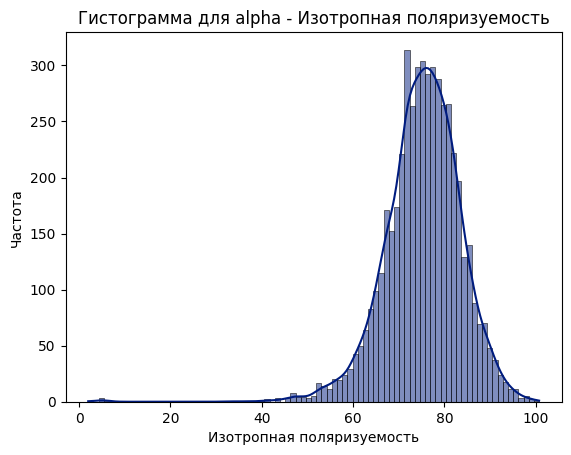

In [5]:
# Построение гистограммы
sns.set_palette("dark")  # Установка стиля
sns.histplot(gap_data['alpha'], kde=True)
plt.title("Гистограмма для alpha - Изотропная поляризуемость")
plt.xlabel("Изотропная поляризуемость")
plt.ylabel("Частота")

# Сохранение графика в PNG
output_path = path.join("graphs", "alpha_histogram.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")  # DPI задает качество, bbox_inches для обрезки лишнег

In [6]:
#Нормализация данных (MinMaxScaler)(маштабирование (переводит значения в каждом числовом столбце в диапазон от 0 до 1))
for col in df.columns:
    if df[col].dtype != 'object':
        min_val = df[col].min()
        max_val = df[col].max()
        df[col] = (df[col] - min_val) / (max_val - min_val)

In [7]:
display(df.head())
display(df.iloc[:, :20].agg(["min", "max"]))

,A,B,C,mu,alpha,homo,lumo,r2,zpve,u0,u298,h298,g298,cv,u0_atom,u298_atom,h298_atom,g298_atom,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,NumRadicalElectrons,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,MinAbsPartialCharge,FpDensityMorgan1,FpDensityMorgan2,FpDensityMorgan3,BCUT2D_MWHI,BCUT2D_MWLOW,BCUT2D_CHGHI,BCUT2D_CHGLO,...,fr_oxime,fr_para_hydroxylation,fr_phenol,fr_phenol_noOrthoHbond,fr_phos_acid,fr_phos_ester,fr_piperdine,fr_piperzine,fr_priamide,fr_prisulfonamd,fr_pyridine,fr_quatN,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,AtomStereoCount,BondStereoCount,XLogP,ExactMass,MonoisotopicMass,TPSA.1,Complexity,Charge,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount.1,IsotopeAtomCount,DefinedAtomStereoCount,UndefinedAtomStereoCount,DefinedBondStereoCount,UndefinedBondStereoCount,CovalentUnitCount
0,0.250894,0.333794,0.362429,0.251268,0.544911,0.012106,0.017908,0.218045,0.022656,0.443922,0.442424,0.445432,0.441661,0.442914,0.502157,0.502583,0.502840,0.496982,0.614869,0.614869,0.173144,0.724674,0.570940,0.501045,0.483716,0.470813,0.483541,0.473684,NaN,0.343574,0.620539,0.379461,0.316510,0.908163,0.945055,0.673469,0.479892,0.484566,0.714645,0.471070,...,0.0,NaN,0.0,0.0,NaN,NaN,0.0,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.000000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.097490,0.069634,0.057731,0.186363,0.762937,0.011154,0.009907,0.607562,0.032956,0.214309,0.213591,0.215043,0.213208,0.755292,0.329031,0.330185,0.330388,0.325004,0.731119,0.731119,0.091675,0.631448,0.490911,0.086179,0.846352,0.823761,0.846093,0.842105,NaN,0.400090,0.594260,0.405740,0.382598,0.928571,0.871795,0.771429,0.468313,0.558505,0.332909,0.584325,...,0.0,NaN,0.0,0.0,NaN,NaN,0.0,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.000000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.113824,0.152228,0.154187,0.070676,0.756962,0.017125,0.021299,0.408099,0.036525,0.248041,0.247207,0.248888,0.246775,0.699003,0.313131,0.313566,0.313642,0.311889,0.616406,0.616406,0.243556,0.826204,0.528951,0.466667,0.835548,0.800327,0.835285,0.842105,NaN,0.189868,0.557936,0.442064,0.136770,0.857143,0.871795,0.733333,0.470168,0.382211,0.703783,0.524852,...,1.0,NaN,0.0,0.0,NaN,NaN,0.0,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.000000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.096243,0.086310,0.069800,0.172249,0.784810,0.014677,0.016325,0.566059,0.038534,0.275153,0.274231,0.276096,0.273742,0.794260,0.255239,0.256218,0.256433,0.251288,0.754691,0.754691,0.028219,0.759985,0.522143,0.092683,0.824699,0.776846,0.824354,0.842105,NaN,0.279766,0.613118,0.386882,0.241894,0.928571,0.871795,0.771429,0.470107,0.526804,0.350764,0.543885,...,0.0,NaN,0.0,0.0,NaN,NaN,0.0,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,0.5,0.0,NaN,NaN,NaN,0.0,0.0,0.166667,0.0,0.447368,0.824354,0.824354,0.2104,0.413934,NaN,0.0,0.333333,0.8,1.0,NaN,NaN,0.166667,NaN,0.0,NaN
4,0.127027,0.157788,0.127321,0.104674,0.767696,0.015969,0.019898,0.427022,0.036993,0.254350,0.253495,0.255219,0.253050,0.693040,0.308381,0.308928,0.309034,0.306717,0.506828,0.506828,0.049361,0.778888,0.435999,0.141463,0.835592,0.800374,0.835409,0.842105,NaN,0.565671,0.488216,0.511784,0.576225,0.857143,0.820513,0.619048,0.470841,0.481940,0.496414,0.391355,...,0.0,NaN,0.0,0.0,NaN,NaN,0.0,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,0.000000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,A,B,C,mu,alpha,homo,lumo,r2,zpve,u0,u298,h298,g298,cv,u0_atom,u298_atom,h298_atom,g298_atom,MaxAbsEStateIndex,MaxEStateIndex
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [8]:
# Выполняем независимый t-тест между 'mu' У которых 'alpha' меньше и больше 0
amidelow = df.loc[df['alpha'] < 0.5, ['mu']]
amidehigh = df.loc[df['alpha'] > 0.5, ['mu']]
t_stat, p_value = ttest_ind(amidelow['mu'], amidehigh['mu'], equal_var=False)
# 3. ANOVA (для сравнения нескольких групп)
anova_result = stats.f_oneway(amidelow['mu'], amidehigh['mu'])

In [9]:
display(pd.DataFrame({"Группа": ["alpha < 0.5", "alpha > 0.5"], "Строк": [len(amidelow), len(amidehigh)]}))
print("t:", t_stat, "p:", p_value)
print("ANOVA:", anova_result)

t: 0.5416222431436797 p: 0.5913631691954533
ANOVA: F_onewayResult(statistic=0.2745961404596936, pvalue=0.6002883538447567)


,Группа,Строк
0,alpha < 0.5,37
1,alpha > 0.5,4975


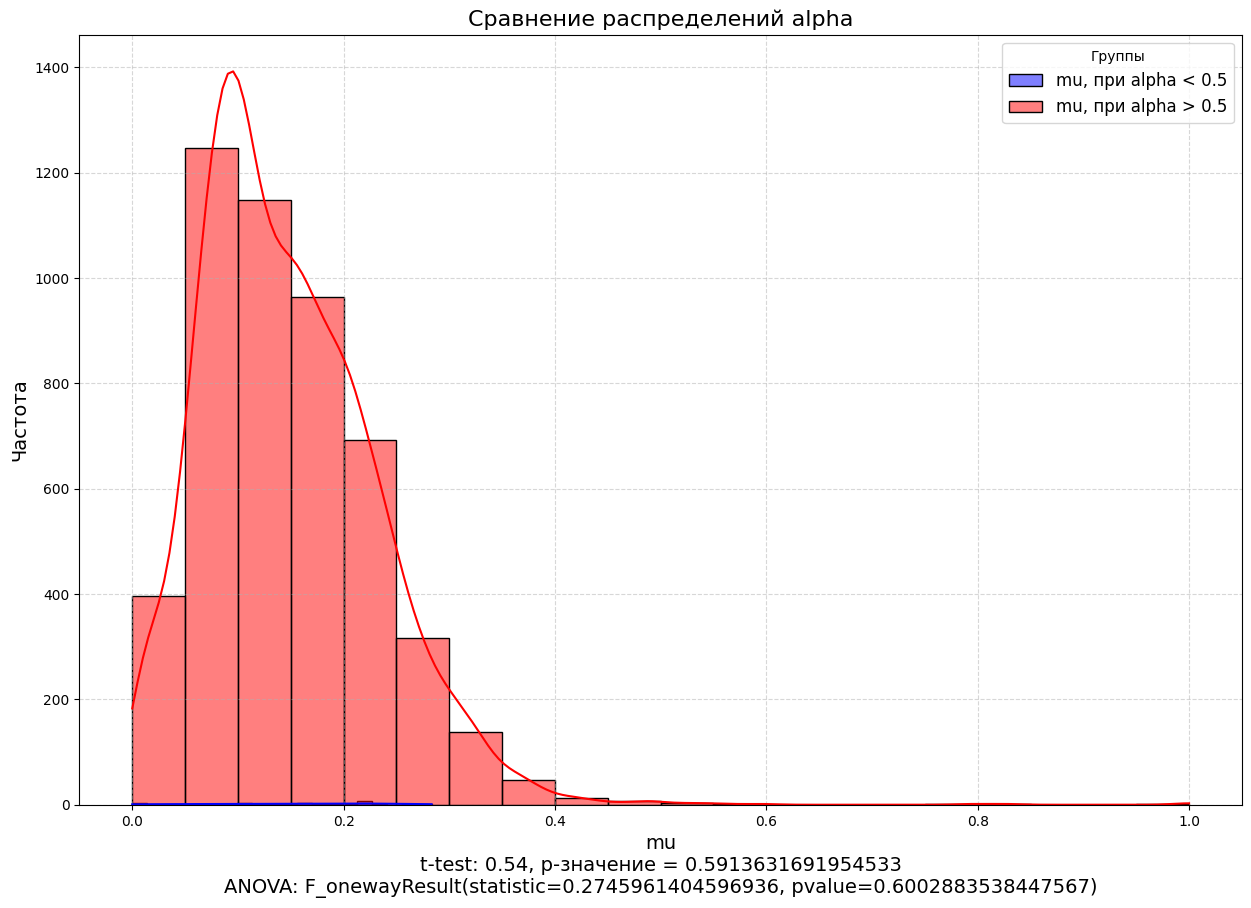

In [10]:
# Построение гистограмм
plt.figure(figsize=(15, 10))  # Установка размеров графика
sns.histplot(amidelow['mu'], color='blue', kde=True, label='mu, при alpha < 0.5', bins=20)
sns.histplot(amidehigh['mu'], color='red', kde=True, label='mu, при alpha > 0.5', bins=20)
# Настройка графика
plt.title("Сравнение распределений alpha", fontsize=16)
plt.xlabel(f"mu\nt-test: {t_stat:.2f}, p-значение = {p_value}\nANOVA: {anova_result}", fontsize=14)
plt.ylabel("Частота", fontsize=14)
plt.legend(title="Группы", fontsize=12)
plt.grid(visible=True, linestyle='--', alpha=0.5)  # Сетка для удобства


output_path = path.join("graphs", "mu_histogram.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")  # DPI задает качество, bbox_inches для обрезки лишнег

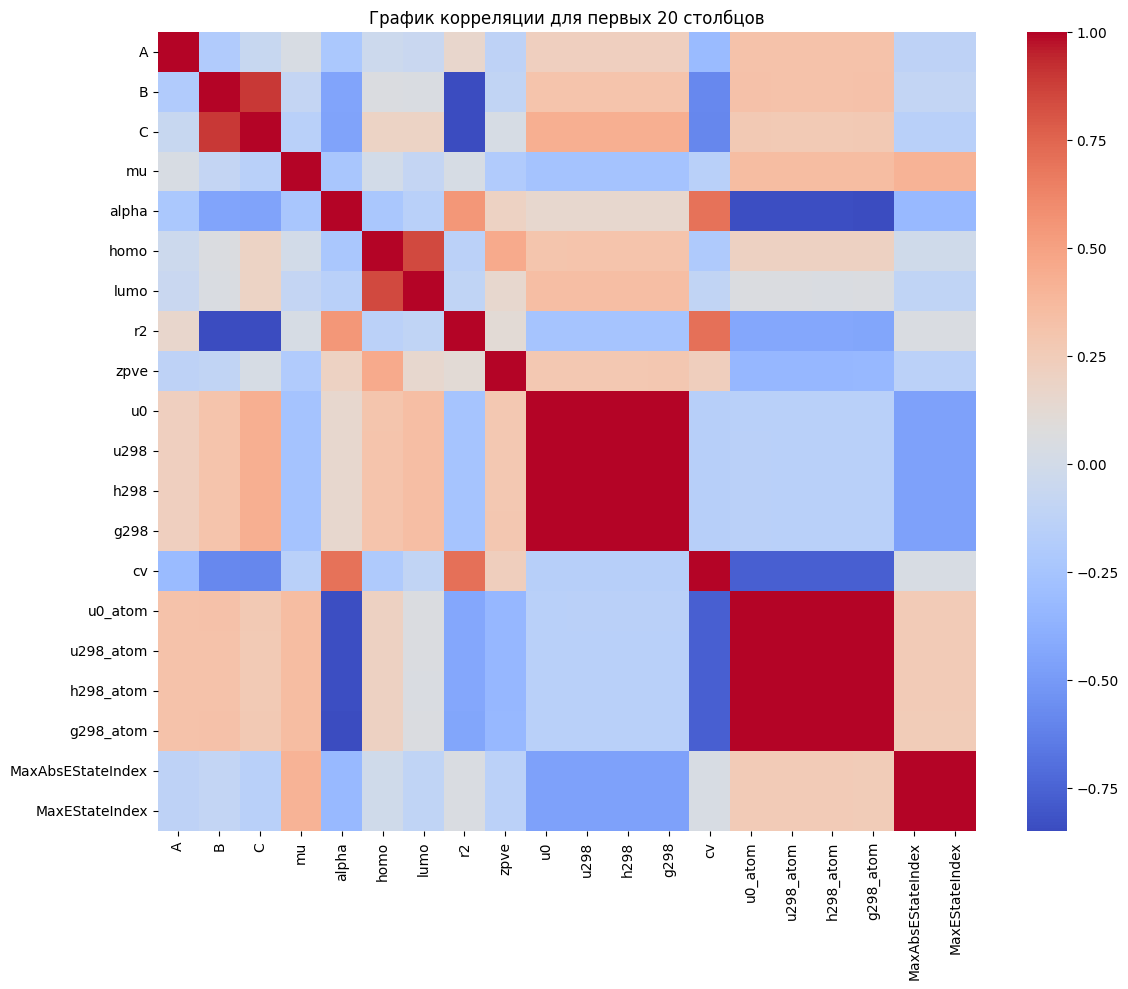

In [11]:
corr = df.iloc[:, :20].corr()

# Построение тепловой карты корреляции
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', annot=False, fmt=".2f", cbar=True)
plt.title("График корреляции для первых 20 столбцов")
plt.tight_layout()
output_path = path.join("graphs", "heatmap.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")  # DPI задает качество, bbox_inches для обрезки лишнег

In [12]:
display(corr)

,A,B,C,mu,alpha,homo,lumo,r2,zpve,u0,u298,h298,g298,cv,u0_atom,u298_atom,h298_atom,g298_atom,MaxAbsEStateIndex,MaxEStateIndex
A,1.000000,-0.192556,-0.067395,0.036910,-0.227512,-0.039010,-0.057683,0.155470,-0.122470,0.226685,0.226607,0.226584,0.226485,-0.315438,0.316999,0.316733,0.316550,0.316585,-0.126351,-0.126351
B,-0.192556,1.000000,0.894978,-0.088593,-0.450314,0.054589,0.052767,-0.850172,-0.099444,0.307146,0.307086,0.307094,0.307079,-0.589189,0.320959,0.319252,0.319263,0.322228,-0.093161,-0.093161
C,-0.067395,0.894978,1.000000,-0.150662,-0.454817,0.190567,0.194664,-0.849282,0.027696,0.434341,0.434378,0.434317,0.434484,-0.595956,0.270799,0.268711,0.268616,0.273385,-0.155538,-0.155538
mu,0.036910,-0.088593,-0.150662,1.000000,-0.242746,-0.002449,-0.089097,0.029030,-0.193922,-0.258661,-0.258595,-0.258586,-0.258483,-0.150075,0.352113,0.352948,0.353100,0.350275,0.410149,0.410149
alpha,-0.227512,-0.450314,-0.454817,-0.242746,1.000000,-0.230672,-0.156096,0.548748,0.203050,0.148276,0.148059,0.148105,0.147681,0.703601,-0.839775,-0.838951,-0.838570,-0.843925,-0.328714,-0.328714
homo,-0.039010,0.054589,0.190567,-0.002449,-0.230672,1.000000,0.846554,-0.137373,0.457700,0.305729,0.306493,0.306248,0.307545,-0.202608,0.206201,0.205672,0.205523,0.208969,-0.017118,-0.017118
lumo,-0.057683,0.052767,0.194664,-0.089097,-0.156096,0.846554,1.000000,-0.112886,0.150004,0.346639,0.347161,0.347626,0.348195,-0.099881,0.054228,0.053422,0.053125,0.058348,-0.106459,-0.106459
r2,0.155470,-0.850172,-0.849282,0.029030,0.548748,-0.137373,-0.112886,1.000000,0.114050,-0.250750,-0.250764,-0.250762,-0.250883,0.705001,-0.437069,-0.435279,-0.435370,-0.438389,0.051737,0.051737
zpve,-0.122470,-0.099444,0.027696,-0.193922,0.203050,0.457700,0.150004,0.114050,1.000000,0.284024,0.284465,0.283383,0.284567,0.230402,-0.337894,-0.338446,-0.338694,-0.334631,-0.135514,-0.135514
u0,0.226685,0.307146,0.434341,-0.258661,0.148276,0.305729,0.346639,-0.250750,0.284024,1.000000,1.000000,0.999999,0.999998,-0.157364,-0.149154,-0.150252,-0.150246,-0.151183,-0.463897,-0.463897


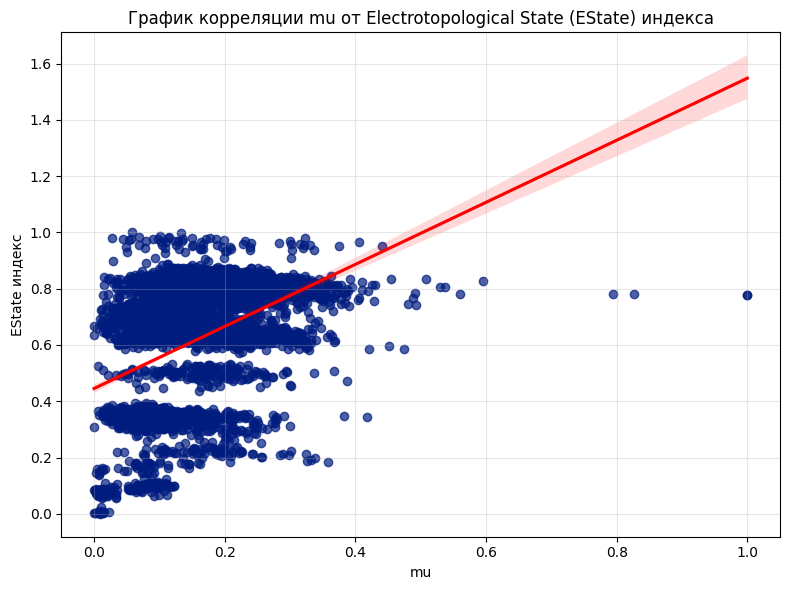

In [13]:
# Построение графика корреляции
sns.set_palette("dark")
plt.figure(figsize=(8, 6))
sns.regplot(x='mu', y='MaxAbsEStateIndex', data=df, scatter_kws={'alpha': 0.7}, line_kws={'color': 'red'})
plt.title("График корреляции mu от Electrotopological State (EState) индекса")
plt.xlabel("mu")
plt.ylabel("EState индекс")
plt.grid(True, alpha=0.3)
plt.tight_layout()
output_path = path.join("graphs", "corr.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")  # DPI задает качество, bbox_inches для обрезки лишнег

In [14]:
conn.close()

In [15]:
print("Готово. Графики сохранены в рабочей папке graphs.")

Готово. Графики сохранены в рабочей папке graphs.
